In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import shutil
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re

from random import randint

### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path("~/ECM_mod_output/").expanduser()
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)
    
LYAP_DIR = Path(SAVEDIR,'Lyap_analysis')
if not os.path.exists(LYAP_DIR):
    os.mkdir(LYAP_DIR)

rcParams.update({'figure.autolayout': True})

### Load UMAP embedding of Lyapunov data
UMAP embeddings should be `LYAP_DIR`. If they are not detected, they will be downloaded automatically.  

NOTE: Compressed LYAP_DIR data is ~50 MB. 

In [3]:
LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f]
if len(LYAP_filepaths) < 2000:
    !wget -O LYAP.zip 'https://www.dropbox.com/scl/fi/hjtuejngyqe78k45utaj7/Lyap_analysis.zip?rlkey=vtl48j839zys324lpnije58nd&dl=1'
    !unzip LYAP.zip
    shutil.rmtree(LYAP_DIR)
    shutil.move('./Lyap_analysis/', SAVEDIR)
    os.remove('./LYAP.zip')
    LYAP_filepaths = [str(Path(LYAP_DIR, f)) for f in os.listdir(LYAP_DIR) if '.csv' in f]

In [4]:
LYAP_filepaths[:5]

['/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_e_erl_range_1_26_192.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_515.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_273.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_d_dmso_range_1_26_267.csv',
 '/Users/darren/ECM_mod_output/Lyap_analysis/embedding_0314_e_erl_range_1_26_838.csv']

In [5]:
filenames_erl = [f for f in LYAP_filepaths if 'embedding_0314_e_erl' in f]
filenames_erl.sort()

ode_divs_erl = np.genfromtxt(Path(LYAP_DIR,'erl_IMT.csv'), delimiter=',')
lyap_erl = np.genfromtxt(Path(LYAP_DIR,'lyap_erl.csv'), delimiter=',')
ode_max = max(ode_divs_erl)
len(filenames_erl)

1000

In [6]:
filenames_dmso = [f for f in LYAP_filepaths if 'embedding_0314_d_dmso' in f]
filenames_dmso.sort()

ode_divs_dmso = np.genfromtxt(Path(LYAP_DIR,'dmso_IMT.csv'), delimiter=',')
lyap_dmso = np.genfromtxt(Path(LYAP_DIR,'lyap_dmso.csv'), delimiter=',')
ode_min = min(ode_divs_erl)
len(filenames_dmso)

1000

In [7]:
tmp_emb = np.genfromtxt(filenames_erl[600], delimiter=',')
tmp_l = len(tmp_emb)
# tmp_l = int(len(tmp_emb)/4)
# tmp_l = 600

In [8]:
size = (8,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

/var/folders/74/mwrshs950kgfbklkltx35bj00000gn/T/ipykernel_43317/2842361761.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')
/Users/darren/miniconda3/envs/ECM_model/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


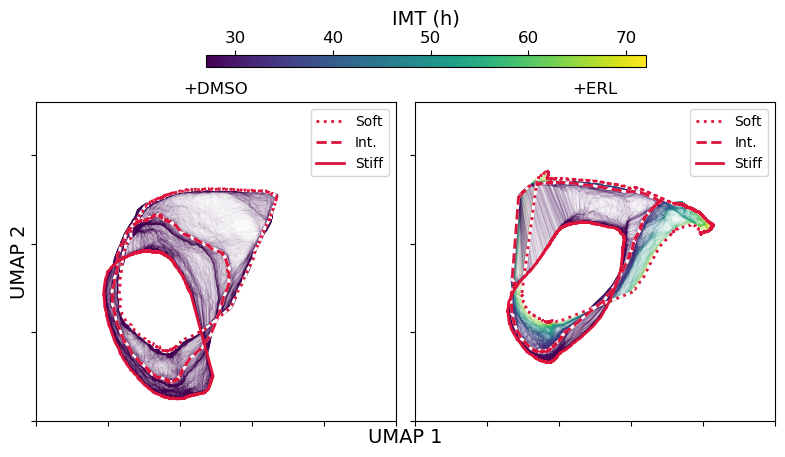

In [9]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_dmso[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_erl[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
# ind = np.where(embedding_index == 112) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='cyan', lw=1)
# ind = np.where(embedding_index == 113) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='magenta', lw=1)
    
    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
# tmp_l = int(len(tmp_emb))
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    
# ii=0
# for num in range(1001,2001):
#     ind = np.where(embedding_index == num) 
#     x=np.ndarray.tolist(embedding_tmp[ind,0])
#     y=np.ndarray.tolist(embedding_tmp[ind,1])
#     axes[0].plot(x[0], y[0], color=cm(norm(ode_divs_dmso[ii])), lw=0.05)
#     ii+=1

tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)    

axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', location='top', label='IMT (h)')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [10]:
norm = plt.Normalize(-0.04, 0)
cm = plt.cm.cividis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

In [11]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [12]:
len(filenames_erl_100)

100

/var/folders/74/mwrshs950kgfbklkltx35bj00000gn/T/ipykernel_43317/433253171.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


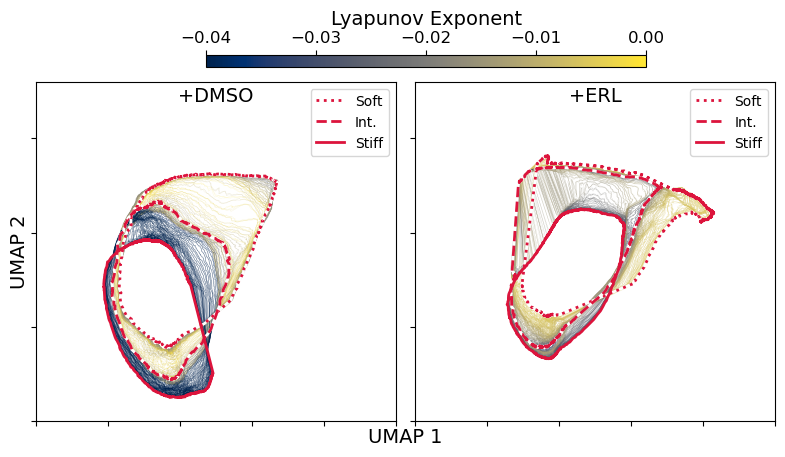

In [13]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.1, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.1, alpha=0.5)
    ii+=1
    

    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    


tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     


axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a_lyap.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [14]:
ode_divs_erl[0]

72.05

In [15]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

(-0.1, 0.02)

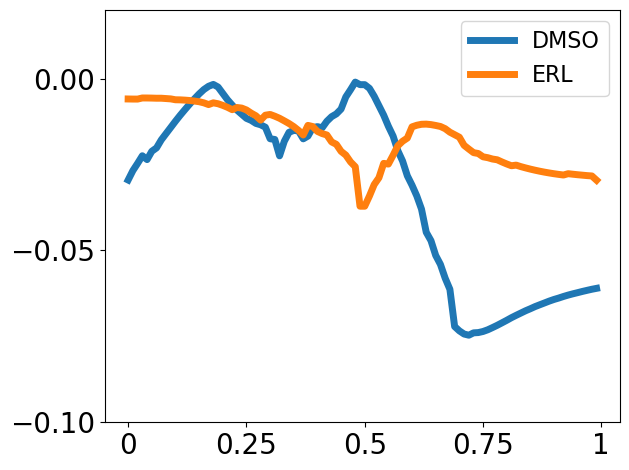

In [16]:
plt.plot(lyap_dmso, label="DMSO", lw=5)
plt.plot(lyap_erl, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 25, 50, 75, 100], [0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.1, -0.05, 0])

plt.ylim(-0.1, 0.02)

### Load base UMAP embedding
needed for plotting ODE overlays

In [ ]:
all_prot_tmp_ode_ab = 


embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [ ]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1

lw = 2


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[2], label='2) 0.3 DMSO')
plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+150,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[1], label='1) 0.0 DMSO')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[3], label='3) 0.7 DMSO')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+100,1], 
         ls='-', lw=lw, alpha=1, color=colors_blue[4], label='4) 1.0 DMSO')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+150,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[1], label='5) 0.0 ERL')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+60,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[3], label='6) 0.5 ERL')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=lw, alpha=1, color=colors_red[4], label='7) 1.0 ERL')

plt.xlim(-5,20)
plt.ylim(0, 15)
plt.xticks(np.arange(-10, 21, step=5))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

handles, labels = plt.gca().get_legend_handles_labels()
order = [1,0,2,3,4,5,6]
plt.legend([handles[idx] for idx in order],[labels[idx] for idx in order], loc="upper right", ncol=2)
# plt.legend(loc="upper right", ncol=2)


plt.savefig(str(SAVE_DIR)+"\\ODEs.svg", format="svg")